# PCA and Logistic Regression on Simulated Genotype Data

**Question:** can we separate two groups using genotypes, and which loci drive the separation?

This notebook does two things:

1. **PCA from scratch with NumPy (SVD)**, then verifies it against scikit-learn
2. **Logistic regression** to classify the group of each individual and rank the most informative loci

**Data note:** the genotypes are **simulated** with 15 loci deliberately differentiated between two groups, so we can check whether the model finds them. This is not real data.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix

rng = np.random.default_rng(2024)

## 1. Simulate genotypes

200 loci, 150 individuals per group. Fifteen loci have their allele frequency shifted by 0.25 in group 1.

In [2]:
n_loci, n_per_group = 200, 150
p_base = rng.uniform(0.1, 0.9, size=n_loci)
diff_loci = rng.choice(n_loci, size=15, replace=False)

p0 = p_base.copy()
p1 = p_base.copy()
p1[diff_loci] = np.where(p_base[diff_loci] > 0.5, p_base[diff_loci] - 0.25, p_base[diff_loci] + 0.25)

X = np.vstack([rng.binomial(2, p0, size=(n_per_group, n_loci)),
               rng.binomial(2, p1, size=(n_per_group, n_loci))]).astype(float)
y = np.repeat([0, 1], n_per_group)          # 0 = group A, 1 = group B

print("X shape (individuals x loci):", X.shape)
print("Planted loci:", sorted(diff_loci.tolist()))

X shape (individuals x loci): (300, 200)
Planted loci: [3, 42, 54, 79, 80, 91, 110, 122, 127, 129, 145, 149, 168, 175, 182]


## 2. PCA from scratch

Steps:
1. Center each locus (subtract its mean) and scale it (divide by its standard deviation).
2. Take the singular value decomposition $Z = U S V^T$.
3. The principal-component scores are $U S$, and the variance explained by each component is proportional to $s_i^2$.

In [3]:
Z = X - X.mean(axis=0)
std = Z.std(axis=0)
std[std == 0] = 1.0
Z = Z / std

U, s, Vt = np.linalg.svd(Z, full_matrices=False)
scores = U * s
explained = s ** 2 / np.sum(s ** 2)

print("Variance explained by PC1-PC5:", np.round(explained[:5], 4))

Variance explained by PC1-PC5: [0.0183 0.0162 0.0153 0.0148 0.0145]


### Verify against scikit-learn

Principal components are only defined up to a sign, so we compare absolute values.

In [4]:
pca = PCA(n_components=5)
sk_scores = pca.fit_transform(Z)

print("Scores match scikit-learn (up to sign):       ", np.allclose(np.abs(scores[:, :5]), np.abs(sk_scores), atol=1e-6))
print("Variance explained matches scikit-learn:      ", np.allclose(explained[:5], pca.explained_variance_ratio_))

Scores match scikit-learn (up to sign):        True
Variance explained matches scikit-learn:       True


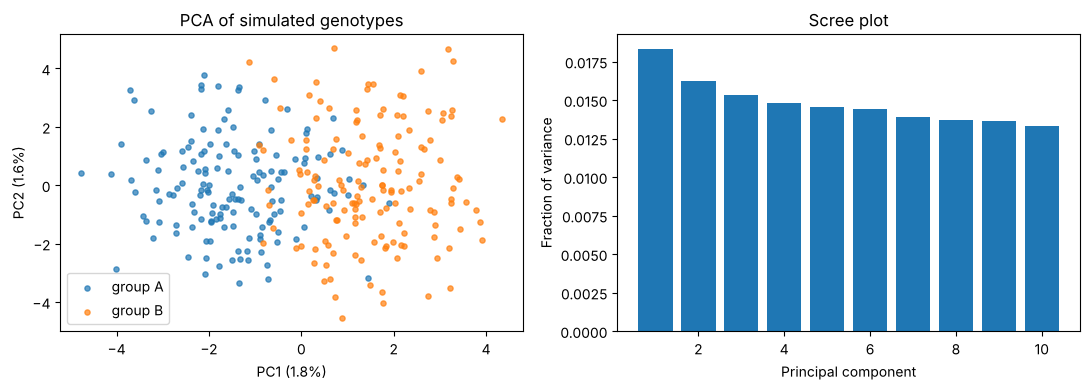

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

for label, color, name in [(0, "tab:blue", "group A"), (1, "tab:orange", "group B")]:
    axes[0].scatter(scores[y == label, 0], scores[y == label, 1], s=14, color=color, label=name, alpha=0.7)
axes[0].set_xlabel("PC1 (%.1f%%)" % (100 * explained[0]))
axes[0].set_ylabel("PC2 (%.1f%%)" % (100 * explained[1]))
axes[0].set_title("PCA of simulated genotypes")
axes[0].legend()

axes[1].bar(np.arange(1, 11), explained[:10])
axes[1].set_xlabel("Principal component")
axes[1].set_ylabel("Fraction of variance")
axes[1].set_title("Scree plot")

plt.tight_layout()
plt.show()

## 3. Logistic regression

We split into training and test sets **first**, then compute the centering and scaling from the training set only. Using the test data to scale would leak information about it into the model.

In [6]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, stratify=y, random_state=0)

mu = X_train.mean(axis=0)
sd = X_train.std(axis=0)
sd[sd == 0] = 1.0
X_train_z = (X_train - mu) / sd
X_test_z = (X_test - mu) / sd

clf = LogisticRegression(C=0.1, max_iter=1000)
clf.fit(X_train_z, y_train)

pred = clf.predict(X_test_z)
print("Test accuracy: %.3f" % accuracy_score(y_test, pred))
print("Confusion matrix (rows = true, columns = predicted):")
print(confusion_matrix(y_test, pred))

Test accuracy: 0.911
Confusion matrix (rows = true, columns = predicted):
[[38  7]
 [ 1 44]]


### Which loci matter?

The size of each coefficient (on standardized genotypes) shows how strongly a locus pushes the prediction. We check whether the 15 largest coefficients are the planted loci.

Top 15 loci by |coefficient|: [3, 42, 54, 79, 80, 91, 110, 122, 127, 129, 145, 153, 168, 175, 182]
Recovered 14 of 15 planted loci: [3, 42, 54, 79, 80, 91, 110, 122, 127, 129, 145, 168, 175, 182]


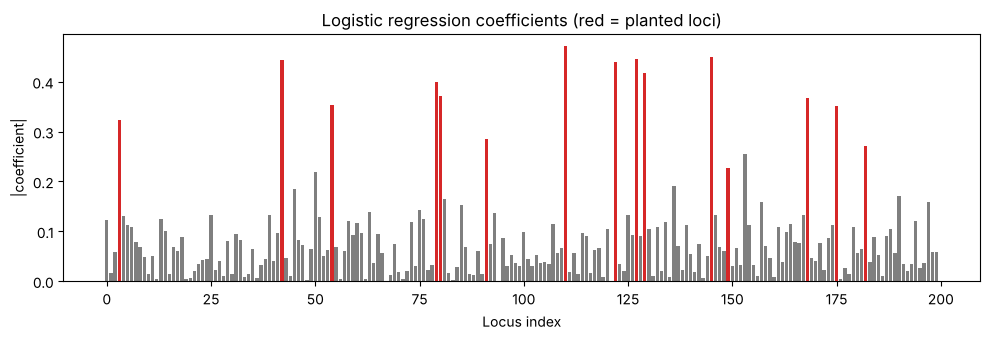

In [7]:
top = np.argsort(np.abs(clf.coef_[0]))[::-1][:len(diff_loci)]
recovered = sorted(set(top.tolist()) & set(diff_loci.tolist()))

print("Top %d loci by |coefficient|: %s" % (len(diff_loci), sorted(top.tolist())))
print("Recovered %d of %d planted loci: %s" % (len(recovered), len(diff_loci), recovered))

plt.figure(figsize=(10, 3.5))
colors = np.where(np.isin(np.arange(n_loci), diff_loci), "tab:red", "tab:gray")
plt.bar(np.arange(n_loci), np.abs(clf.coef_[0]), color=colors)
plt.xlabel("Locus index")
plt.ylabel("|coefficient|")
plt.title("Logistic regression coefficients (red = planted loci)")
plt.tight_layout()
plt.show()

## Check your understanding

1. Why do we center and scale each locus before PCA?
2. The groups are visibly shifted along PC1, yet PC1 explains only a small fraction of the total variance (see the scree plot). Why? (Hint: how many of the 200 loci actually differ between the groups?) And why can logistic regression still classify well when PCA shows only partial separation?
3. Why do we split the data before computing the scaling parameters for logistic regression?
4. The model is accurate on the test set. Why is that not enough to claim the top-ranked loci are causal in real data?

## Limitations

- The groups here differ at independent loci. Real genomes have linkage disequilibrium, so neighbouring loci carry correlated signal and the model's top loci may be proxies for the causal ones.
- A single train/test split gives a noisy accuracy estimate. Use cross-validation for reporting.
- Simulated data shows the workflow functions on a clean case. It is not evidence about any real population.